# EfficientNet_01: EfficientNet-B0 on the main split (44 species, clip-level)

**Recipe (2025, unchanged):** ImageNet EfficientNet-B0, full fine-tuning, batch 16, AdamW lr 1e-3 / wd 1e-4,
class-weighted cross-entropy, ReduceLROnPlateau (×0.5, patience 2), grad clip 1.0, max 10 epochs,
early stopping patience 3, best checkpoint = lowest val loss. Additions: seed 42, mixed precision on GPU.

**Input:** 128-mel spectrogram, first 400 frames (~4.65 s at 44 kHz).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src import config
print("data root:", config.DATA_ROOT)
import pandas as pd, matplotlib.pyplot as plt, torch
RUN, SPLIT, SPLIT_DIR = "EfficientNet_01", "main", config.MAIN_SPLIT_DIR
print(RUN, SPLIT, SPLIT_DIR, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

data root: D:\UNI&WORK\Watkins


EfficientNet_01 main D:\UNI&WORK\Watkins\Annotations | GPU: NVIDIA GeForce RTX 5050 Laptop GPU


## Data check

In [2]:
parts = {s: pd.read_csv(SPLIT_DIR / f"{s}.csv") for s in ["train", "val", "test"]}
print({s: len(p) for s, p in parts.items()}, "| species:", parts["train"].category.nunique(),
      "| recordings shared train/test:", len(set(parts["train"].recording) & set(parts["test"].recording)))

{'train': 9868, 'val': 2115, 'test': 2115} | species: 44 | recordings shared train/test: 297


## Train

In [3]:
from src.EfficientNet.train import Trainer, next_checkpoint_path
ckpt = next_checkpoint_path(RUN)
trainer = Trainer(SPLIT_DIR, ckpt)
trainer.fit()

caching train.csv:   0%|          | 0/9868 [00:00<?, ?it/s]

caching train.csv:  14%|█▍        | 1371/9868 [00:30<03:05, 45.69it/s]

caching train.csv:  14%|█▍        | 1371/9868 [00:40<03:05, 45.69it/s]

caching train.csv:  28%|██▊       | 2762/9868 [01:00<02:34, 46.08it/s]

caching train.csv:  28%|██▊       | 2762/9868 [01:10<02:34, 46.08it/s]

caching train.csv:  46%|████▌     | 4513/9868 [01:30<01:43, 51.69it/s]

... (23 outputs left out)

Epoch 9/10 | train loss 0.1557 acc 97.01 | val loss 0.1479 acc 96.69 | lr 1.00e-03 | 38s


  saved best checkpoint -> efficientnet_01_best_01.pth


Epoch 10/10 | train loss 0.1408 acc 97.19 | val loss 0.1892 acc 96.12 | lr 1.00e-03 | 38s


Training finished.


,epoch,train_loss,val_loss,train_acc,val_acc,lr,seconds
0,1,1.978128,0.675728,59.8095,81.5130,0.001,130.4
1,2,0.869010,0.372260,81.3133,88.2742,0.001,37.3
2,3,0.549304,0.372482,87.6165,90.1182,0.001,36.2
3,4,0.361857,0.293734,91.9133,91.8203,0.001,35.7
4,5,0.264785,0.215992,94.0819,93.9007,0.001,38.0
5,6,0.197690,0.258216,95.2371,94.3262,0.001,38.3
6,7,0.151430,0.175283,95.7033,96.6903,0.001,38.5
7,8,0.167080,0.258519,96.8383,95.7447,0.001,38.7
8,9,0.155683,0.147886,97.0105,96.6903,0.001,38.2
9,10,0.140817,0.189207,97.1929,96.1229,0.001,38.0


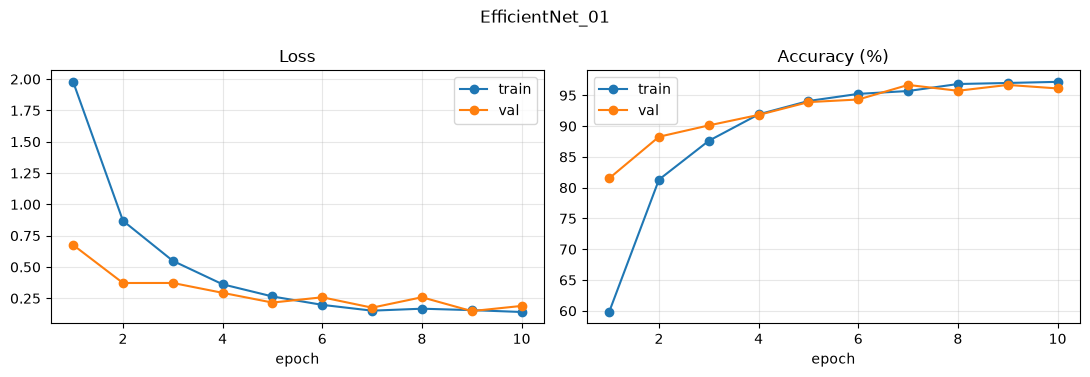

In [4]:
from src.plot_analysis import plot_learning_curves
config.EVAL_DIR.mkdir(parents=True, exist_ok=True)
plot_learning_curves(trainer.history_path, RUN, config.EVAL_DIR / f"learning_curves_{RUN}.png");
pd.read_csv(trainer.history_path)

## Test-set evaluation (best checkpoint)

In [5]:
from src.evaluate import predict, save_evaluation
y, yp, probs = predict(trainer.model, trainer.test_loader, trainer.device)
m = save_evaluation(RUN, SPLIT, trainer.classes, trainer.test_loader.dataset.filenames, y, yp, probs)
pd.Series(m).round(4)

accuracy              0.9707
precision_macro       0.9543
recall_macro          0.9514
f1_macro              0.9441
precision_weighted    0.9726
recall_weighted       0.9707
f1_weighted           0.9702
dtype: float64

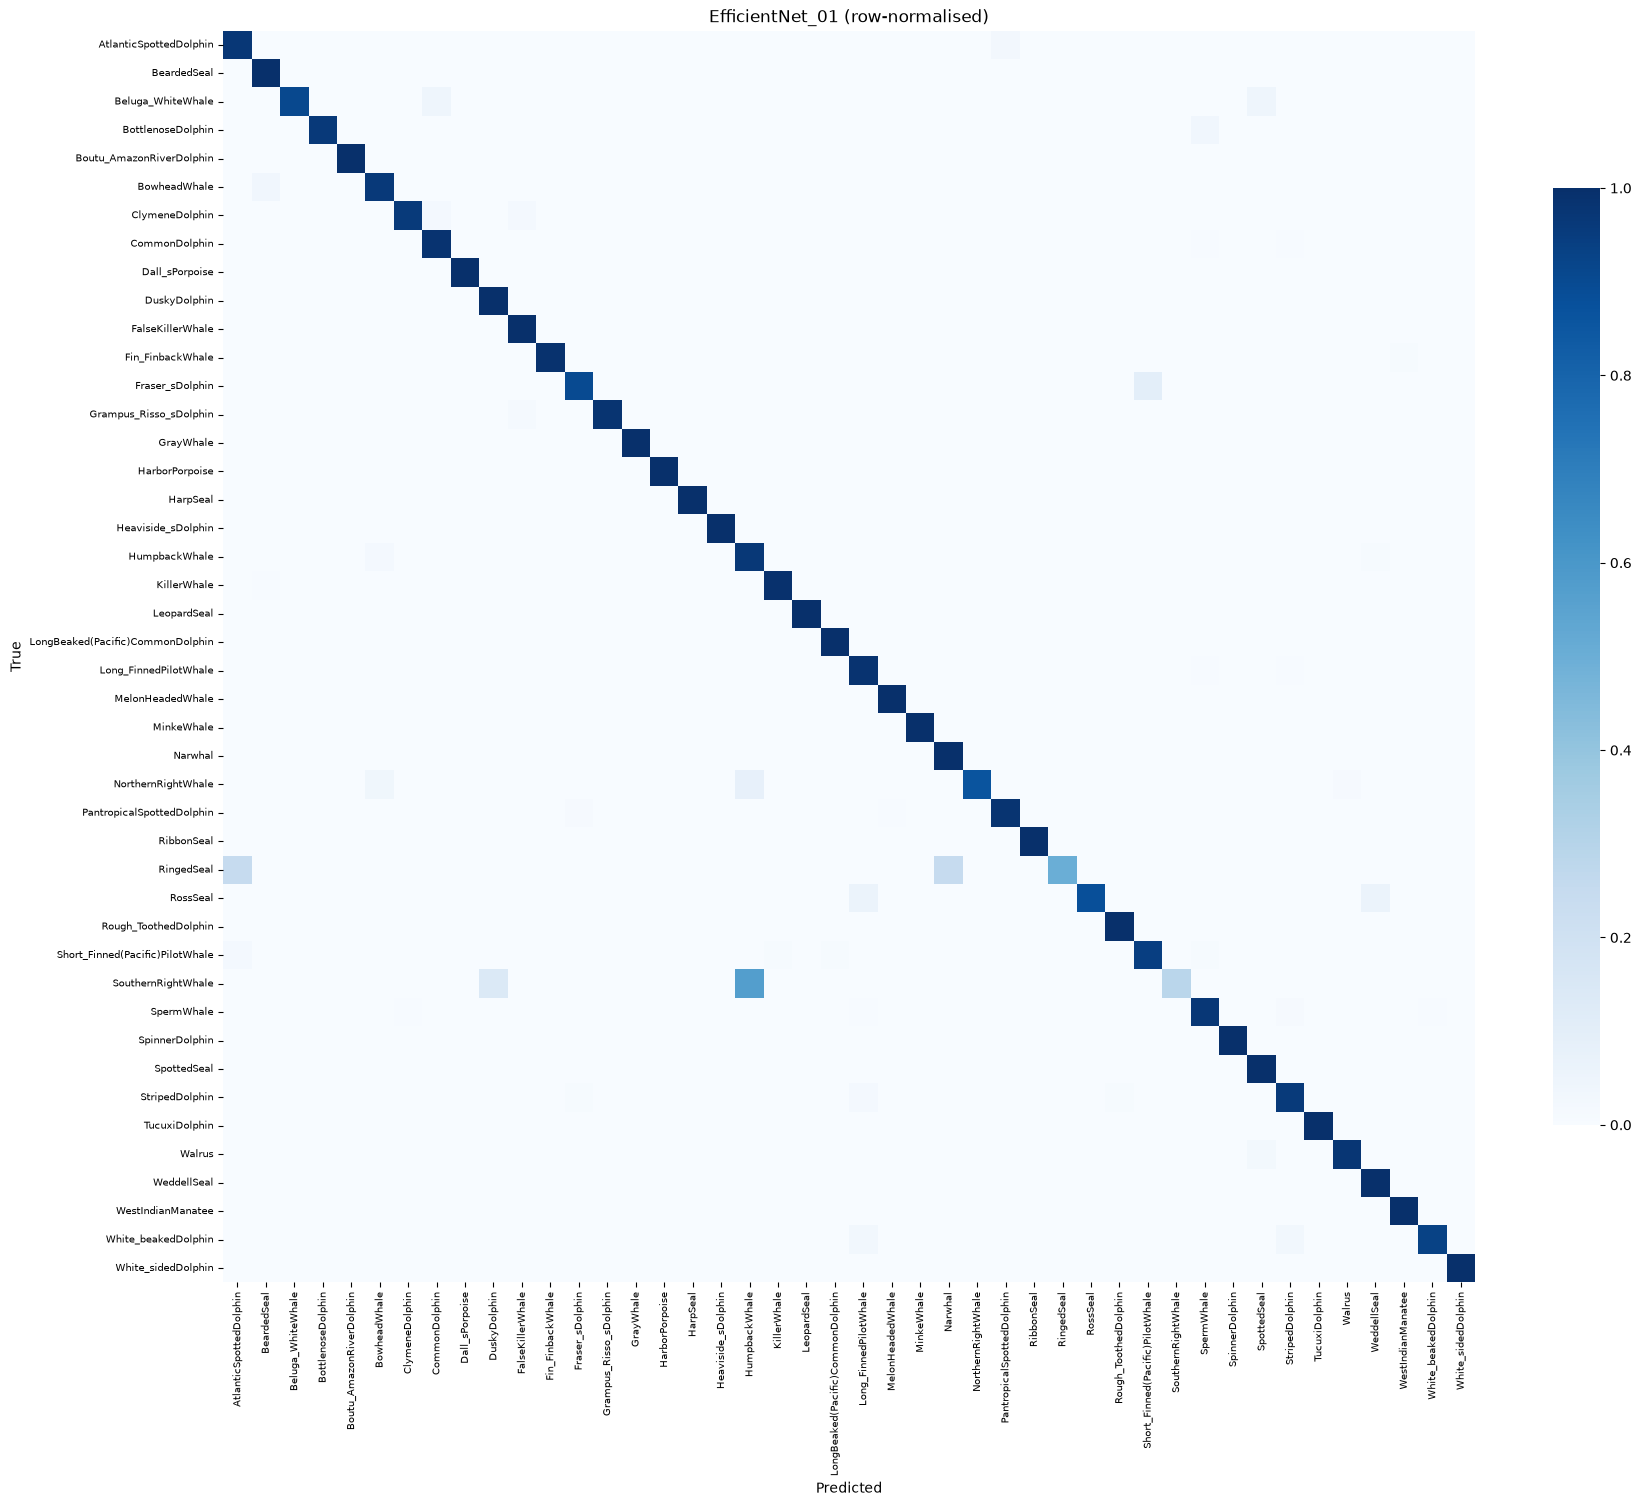

In [6]:
from src.plot_analysis import plot_confusion_matrix, plot_per_class_f1
cm = pd.read_csv(config.EVAL_DIR / f"confusion_matrix_{RUN}.csv", index_col=0).values
plot_confusion_matrix(cm, trainer.classes, f"{RUN} (row-normalised)", config.EVAL_DIR / f"confusion_matrix_{RUN}.png");

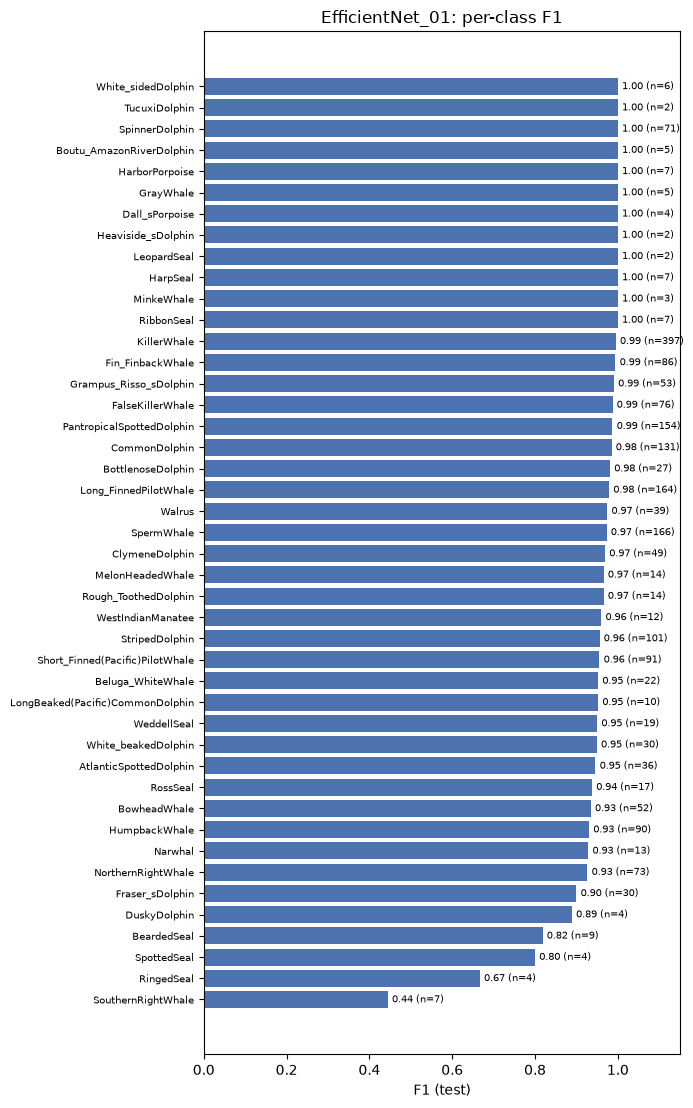

In [7]:
plot_per_class_f1(config.EVAL_DIR / f"classification_report_{RUN}.csv", f"{RUN}: per-class F1",
                  config.EVAL_DIR / f"per_class_f1_{RUN}.png");

In [8]:
rep = pd.read_csv(config.EVAL_DIR / f"classification_report_{RUN}.csv", index_col=0)
rep = rep.drop(index=["accuracy", "macro avg", "weighted avg"])
print("Hardest classes:"); rep.sort_values("f1-score").head(10).round(3)

Hardest classes:


,precision,recall,f1-score,support
SouthernRightWhale,1.000,0.286,0.444,7.0
RingedSeal,1.000,0.500,0.667,4.0
SpottedSeal,0.667,1.000,0.800,4.0
BeardedSeal,0.692,1.000,0.818,9.0
DuskyDolphin,0.800,1.000,0.889,4.0
Fraser_sDolphin,0.900,0.900,0.900,30.0
NorthernRightWhale,1.000,0.863,0.926,73.0
Narwhal,0.867,1.000,0.929,13.0
HumpbackWhale,0.897,0.967,0.930,90.0
BowheadWhale,0.909,0.962,0.935,52.0
